<a href="https://colab.research.google.com/github/09StevenG/C.V.-Steven-Guill-n/blob/main/Tarea3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1334]:
!pip install -q pysheds # Librería para el procesamiento rápido en DEM y
# análisis hidrológico


In [1335]:
import rasterio #vamos a manejar rasters
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio import features
from rasterio.merge import merge
from rasterio.plot import show #para poder pre-visualizar

In [1336]:
#casi todas estas las usamos para visualizar datos y geometrias
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium


In [1337]:
#transformación de coordenadas
from shapely.geometry import shape
from pyproj import Transformer

In [1338]:
import os #si vamos a generar archivos i/o (crear un archivo al disco o viceversa)
import math #calculos matematicos de cajón

In [1339]:
# la libreria de pysheds
from pysheds.grid import Grid
print("Iniciar")

Iniciar


# Proceso para extracción del DEM en área de interés.


In [1340]:
import os
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.merge import merge

# Esta línea le dice a la librería que no ande listando carpetas remotas.
# Sin ella, leer desde la nube es varias veces más lento.
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

print("rasterio", rasterio.__version__)

rasterio 1.5.2


In [1341]:
#funciones para extraer datos de COPERNICUS solo correrlo

def _url_tesela(lat, lon, glo=30):
    """Arma la dirección del archivo de una tesela de Copernicus."""
    res = "10" if glo == 30 else "30"          # resolución en segundos de arco
    ns = "N" if lat >= 0 else "S"
    ew = "E" if lon >= 0 else "W"
    nombre = (f"Copernicus_DSM_COG_{res}_"
              f"{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM")
    return f"https://copernicus-dem-{glo}m.s3.amazonaws.com/{nombre}/{nombre}.tif"


def obtener_dem(lat_min, lon_min, lat_max, lon_max):
    """Devuelve el DEM recortado al recuadro, como matriz y perfil."""
    teselas = [(la, lo)
               for la in range(math.floor(lat_min), math.floor(lat_max) + 1)
               for lo in range(math.floor(lon_min), math.floor(lon_max) + 1)]

    for glo in (30, 90):
        abiertas = []
        try:
            for la, lo in teselas:
                abiertas.append(rasterio.open(_url_tesela(la, lo, glo)))
        except Exception:
            for a in abiertas:
                a.close()
            print(f"GLO-{glo}: falta al menos una tesela de esta zona.")
            continue

        mosaico, transform = merge(
            abiertas, bounds=(lon_min, lat_min, lon_max, lat_max)
        )
        perfil = abiertas[0].profile
        for a in abiertas:
            a.close()

        perfil.update(driver="GTiff", count=1,
                      height=mosaico.shape[1], width=mosaico.shape[2],
                      transform=transform)

        print(f"Copernicus GLO-{glo} · {len(teselas)} tesela(s)")
        print(f"{mosaico.shape[2]} x {mosaico.shape[1]} celdas")
        return mosaico[0], perfil

    raise RuntimeError("Esa área no tiene cobertura en GLO-30 ni en GLO-90.")

In [1342]:
# área de interés: Microcuenca Río Tatiscú, Cartago
LAT_MIN, LAT_MAX = 9.820000, 9.940000      # sur, norte
LON_MIN, LON_MAX = -83.940000, -83.870000  # oeste, este

NOMBRE_AREA = "Microcuenca Río Tatiscú"  # para los títulos de los mapas

print(f"Área: {NOMBRE_AREA}")
print(f"  latitud  de {LAT_MIN} a {LAT_MAX}")
print(f"  longitud de {LON_MIN} a {LON_MAX}")

Área: Microcuenca Río Tatiscú
  latitud  de 9.82 a 9.94
  longitud de -83.94 a -83.87


In [1343]:
#acá se usan las funciones, queda la data del raster en z
z, perfil = obtener_dem(LAT_MIN, LON_MIN, LAT_MAX, LON_MAX)

Copernicus GLO-30 · 1 tesela(s)
252 x 432 celdas


In [1344]:
#inspeccionar
print("Dimensiones :", z.shape, "(filas, columnas)")
print("CRS         :", perfil["crs"])
print("Valor nulo  :", perfil["nodata"])
print("Bandas      :", perfil["count"])
print("Tipo de dato:", perfil["dtype"])

Dimensiones : (432, 252) (filas, columnas)
CRS         : EPSG:4326
Valor nulo  : None
Bandas      : 1
Tipo de dato: float32


In [1345]:
#verificar transform
t = perfil["transform"]

print(f"Tamaño de celda: {abs(t.a):.6f} x {abs(t.e):.6f} grados")
print(f"Es decir, unos {abs(t.a) * 111320:.0f} metros de lado")

Tamaño de celda: 0.000278 x 0.000278 grados
Es decir, unos 31 metros de lado


Archivo guardado como: Microcuenca_Río_Tatiscú_DEM.tif


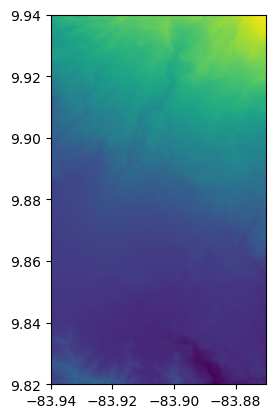

In [1346]:
from rasterio.plot import show #para verlo



# Definir el nombre del archivo de salida
nombre_archivo = f"{NOMBRE_AREA.replace(' ', '_')}_DEM.tif"

# 1. Guardar el raster a un archivo GeoTIFF local usando el perfil actualizado
with rasterio.open(nombre_archivo, 'w', **perfil) as dst:
    dst.write(z, 1)

print(f"Archivo guardado como: {nombre_archivo}")

# 2. Volver a abrir el raster y leerlo para verificar y mostrar el mapa
with rasterio.open(nombre_archivo) as src:
    data_leida = src.read(1)

    show(src)

In [1347]:
#el input de pysheds es un DEM
DEM = "Microcuenca Río Tatiscú"

In [1348]:
#funciones que deberíamos tener al alcance
def reproyectar(src_path, dst_path, dst_crs):
    """Pasa un ráster a otro sistema de coordenadas."""
    with rasterio.open(src_path) as src:
        t, w, h = calculate_default_transform(
            src.crs, dst_crs, src.width, src.height, *src.bounds)
        perfil = src.profile.copy()
        perfil.update(crs=dst_crs, transform=t, width=w, height=h, driver="GTiff")

        with rasterio.open(dst_path, "w", **perfil) as dst:
            reproject(source=rasterio.band(src, 1),
                      destination=rasterio.band(dst, 1),
                      src_transform=src.transform, src_crs=src.crs,
                      dst_transform=t, dst_crs=dst_crs,
                      src_nodata=src.nodata, dst_nodata=src.nodata,
                      resampling=Resampling.bilinear)
    return dst_path

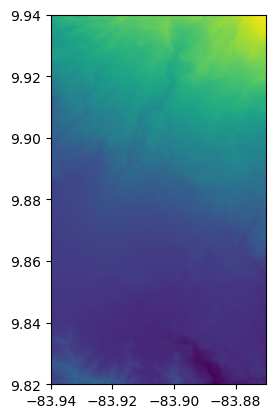

Zona UTM: EPSG:32617


In [1349]:
with rasterio.open(nombre_archivo.strip()) as d:
    b = d.bounds #obtiene la caja del raster
    marco = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy([b.left, b.right], [b.bottom, b.top]),
        crs=d.crs)
    UTM = marco.estimate_utm_crs() ## geopandas con un bound (caja en lat,lon)
    show(d) ##previsualizar el raster

print("Zona UTM:", UTM.to_string())

In [1350]:
#reproyectamos este raster
reproyectar(nombre_archivo.strip(), "Microcuenca_Río_Tatiscú_reproyectado.tif", UTM)

'Microcuenca_Río_Tatiscú_reproyectado.tif'

Dimensiones: 254 x 435
Celda      : 30.69 x 30.69 m
Área de celda: 942 m2


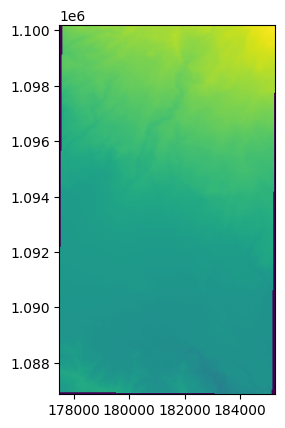

In [1351]:
with rasterio.open("Microcuenca_Río_Tatiscú_reproyectado.tif") as d:
    print("Dimensiones:", d.width, "x", d.height)
    print(f"Celda      : {abs(d.transform.a):.2f} x {abs(d.transform.e):.2f} m")
    CELDA = abs(d.transform.a) * abs(d.transform.e)
    print(f"Área de celda: {CELDA:.0f} m2")
    show(d)

In [1352]:
##paso 2 - acondicionamiento del terreno
## paso 2.1 leer el raster con Pysheds
grid = Grid.from_raster("Microcuenca_Río_Tatiscú_reproyectado.tif")
dem  = grid.read_raster("Microcuenca_Río_Tatiscú_reproyectado.tif")

/usr/local/lib/python3.13/dist-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')
/usr/local/lib/python3.13/dist-packages/pysheds/io.py:134: UserWarning: No `nodata` value detected. Defaulting to 0.
  warnings.warn('No `nodata` value detected. Defaulting to 0.')


In [1353]:
#acondicionar el terreno, (fill_pits, fill_depressions,resolve_flats)


pit      = grid.fill_pits(dem) #ajustar pixeles aislados que estén hundidos o salidos
flood    = grid.fill_depressions(pit) ## los rellenamos
inflated = grid.resolve_flats(flood) ##pendiente artificial ( ajustados)

print("celdas modificadas por fill_pits        :",
      int((np.asarray(pit) != np.asarray(dem)).sum()))
print("celdas modificadas por fill_depressions :",
      int((np.asarray(flood) != np.asarray(pit)).sum()))

celdas modificadas por fill_pits        : 1970
celdas modificadas por fill_depressions : 0


In [1354]:
##algebra de mapas, vamos a comparar visualmente pixels que fueron cambiados
diferencia = np.asarray(inflated) - np.asarray(dem) #determinar diferencias entre original y acondicionado
tocadas = diferencia > 0 #pixels modificados

print(f"Celdas modificadas  : {int(tocadas.sum()):,} de {diferencia.size:,} "
      f"({tocadas.sum()/diferencia.size*100:.2f} %)")
if tocadas.any():
    print(f"Levantamiento medio : {diferencia[tocadas].mean():.3f} m")
    print(f"Levantamiento máximo: {diferencia[tocadas].max():.2f} m")

Celdas modificadas  : 4,172 de 110,490 (3.78 %)
Levantamiento medio : 0.753 m
Levantamiento máximo: 26.59 m


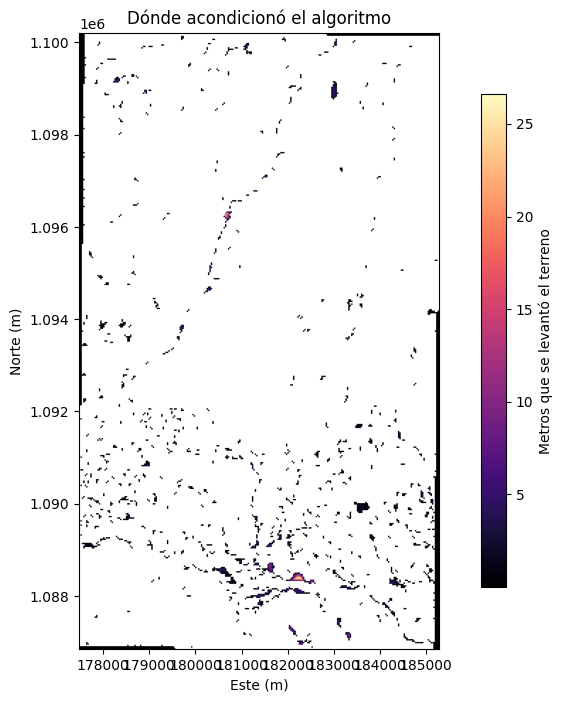

In [1355]:
plt.figure(figsize=(11, 8))
plt.imshow(np.where(tocadas, diferencia, np.nan), cmap="magma",
           extent=grid.extent)
plt.colorbar(label="Metros que se levantó el terreno", shrink=0.8)
plt.title("Dónde acondicionó el algoritmo")
plt.xlabel("Este (m)"); plt.ylabel("Norte (m)")
plt.show()

In [1356]:
##paso 3 calculo de dirección de flujo
dirmap = (64, 128, 1, 2, 4, 8, 16, 32)
#          N  NE   E  SE  S  SO   O  NO

fdir = grid.flowdir(inflated, dirmap=dirmap)

print("Direcciones calculadas:", fdir.shape)
print("Valores que aparecen  :", sorted(np.unique(np.asarray(fdir))[:10]))

Direcciones calculadas: (435, 254)
Valores que aparecen  : [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64)]


In [1357]:
#paso 4 calculo de acumuliación
acc = grid.accumulation(fdir, dirmap=dirmap)
a = np.asarray(acc)          # copia NumPy, para contar y graficar

print(f"Acumulación máxima: {int(a.max()):,} celdas")
print(f"Es decir, el cauce principal drena {a.max()*CELDA/1e6:,.0f} km2")

Acumulación máxima: 56,634 celdas
Es decir, el cauce principal drena 53 km2


In [1358]:
#para verificar la red de drenaje se debe definir un umbral
for u in [100, 500, 1000, 5000, 20000]:
    n = int((a > u).sum())
    print(f"umbral {u:>6,} celdas ({u*CELDA/1e6:6.2f} km2) -> "
          f"{n:>7,} celdas de cauce ~ {n*abs(grid.affine.a)/1000:7.1f} km de red")

umbral    100 celdas (  0.09 km2) ->   7,829 celdas de cauce ~   240.2 km de red
umbral    500 celdas (  0.47 km2) ->   3,933 celdas de cauce ~   120.7 km de red
umbral  1,000 celdas (  0.94 km2) ->   2,797 celdas de cauce ~    85.8 km de red
umbral  5,000 celdas (  4.71 km2) ->     844 celdas de cauce ~    25.9 km de red
umbral 20,000 celdas ( 18.83 km2) ->      95 celdas de cauce ~     2.9 km de red


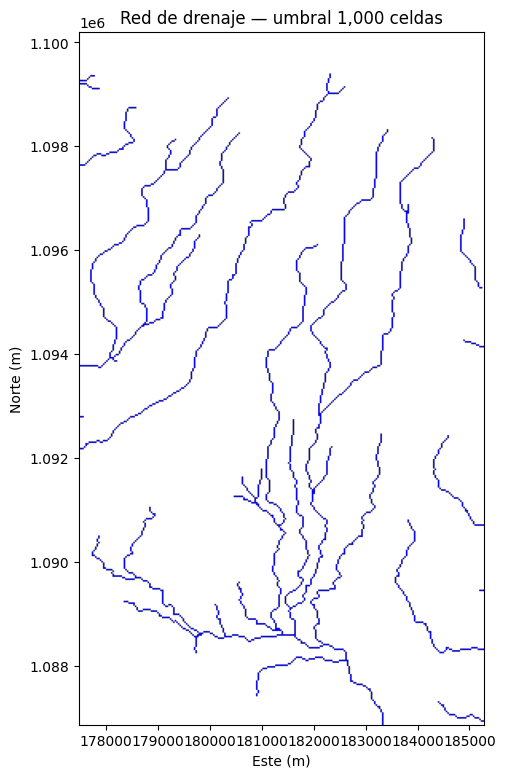

In [1359]:
UMBRAL = 1000          # celdas; ~0.9 km2 de área drenada

# Ojo: cauces se deja como objeto de pysheds, no como arreglo de NumPy.
# snap_to_mask lo necesita así. Para dibujar usamos np.asarray(cauces).
cauces = acc > UMBRAL
cauces_np = np.asarray(cauces)

plt.figure(figsize=(11, 9))
plt.imshow(np.where(cauces_np, 1, np.nan), cmap="winter", extent=grid.extent)
plt.title(f"Red de drenaje — umbral {UMBRAL:,} celdas")
plt.xlabel("Este (m)"); plt.ylabel("Norte (m)")
plt.show()

In [1360]:
# Punto de salida

In [1361]:
hacia_utm_p = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)
x0p, y0p = hacia_utm_p.transform(-83.902222,9.836388)


def probar(etiqueta, superficie):
    fd = grid.flowdir(superficie, dirmap=dirmap)
    ac = grid.accumulation(fd, dirmap=dirmap)
    sx, sy = grid.snap_to_mask(ac > UMBRAL, (x0p, y0p))
    cu = grid.catchment(x=sx, y=sy, fdir=fd, dirmap=dirmap, xytype="coordinate")
    print(f"{etiqueta:32s} acc máx {int(np.asarray(ac).max()):>9,} | "
          f"cuenca {np.asarray(cu).sum()*CELDA/1e6:7.2f} km2")


probar("1. crudo, sin acondicionar", dem)
probar("2. solo fill_pits", pit)
probar("3. + fill_depressions", flood)
probar("4. + resolve_flats (completo)", inflated)

1. crudo, sin acondicionar       acc máx     4,750 | cuenca    1.75 km2
2. solo fill_pits                acc máx     4,731 | cuenca    1.75 km2
3. + fill_depressions            acc máx     4,731 | cuenca    1.75 km2
4. + resolve_flats (completo)    acc máx    56,634 | cuenca   16.50 km2


In [1362]:
LON_SALIDA, LAT_SALIDA = -83.902222,9.836388
hacia_utm = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)
hacia_geo = Transformer.from_crs(UTM, "EPSG:4326", always_xy=True)

x0, y0 = hacia_utm.transform(LON_SALIDA, LAT_SALIDA) #mi punto
x, y = grid.snap_to_mask(cauces, (x0, y0)) ### se debe SNAP_to_MASK (pedirle al pysheds que
#                                          ### lo coloque sobre el punto de la red de drenaje mas cercana
##pysheds por medio de este método snap_to_mask determina el pour point correcto.

print(f"Punto dado  : {LON_SALIDA}, {LAT_SALIDA}")
print(f"Punto pegado: {hacia_geo.transform(x, y)[0]:.5f}, {hacia_geo.transform(x, y)[1]:.5f}")
print(f"Se movió {((x-x0)**2 + (y-y0)**2)**0.5:.0f} metros")

Punto dado  : -83.902222, 9.836388
Punto pegado: -83.90241, 9.83638
Se movió 21 metros


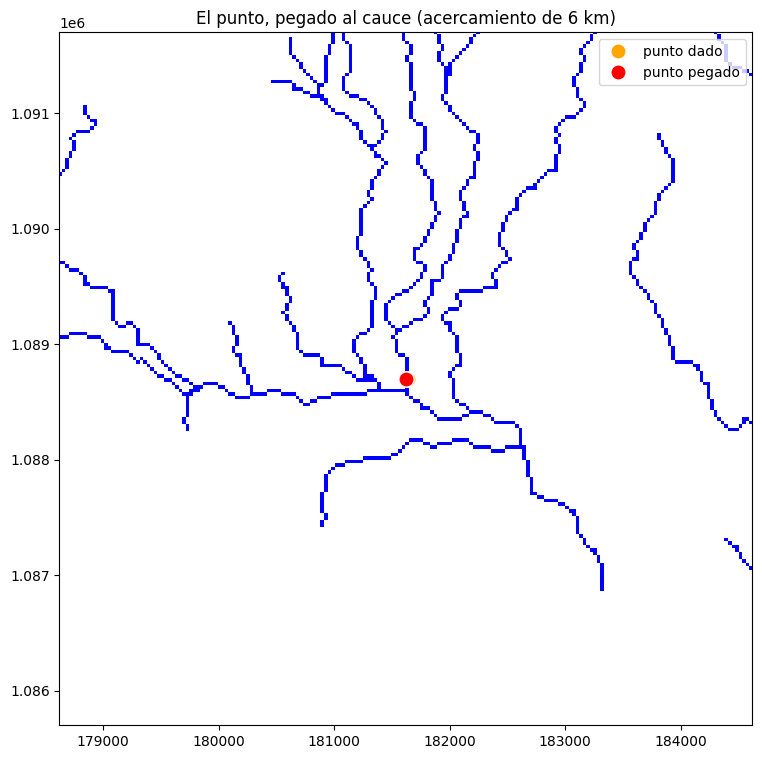

In [1363]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(np.where(cauces_np, 1, np.nan), cmap="winter", extent=grid.extent)
ax.plot(x0, y0, "o", color="orange", markersize=11,
        markeredgecolor="white", label="punto dado")
ax.plot(x, y, "o", color="red", markersize=11,
        markeredgecolor="white", label="punto pegado")
ax.set_xlim(x - 3000, x + 3000)
ax.set_ylim(y - 3000, y + 3000)
ax.legend()
ax.set_title("El punto, pegado al cauce (acercamiento de 6 km)")
plt.show()

In [1364]:
##
cuenca = grid.catchment(x=x, y=y, fdir=fdir, dirmap=dirmap,
                        xytype="coordinate")
m = np.asarray(cuenca)
n_celdas = int(m.sum())

print(f"{n_celdas:,} celdas")
print(f"Área: {n_celdas * CELDA / 1000000:.2f} km2")

17,524 celdas
Área: 16.50 km2


In [1365]:
mask = m.astype(np.uint8)
polis = [shape(g) for g, v in features.shapes(mask, mask=m, transform=grid.affine)
         if v == 1]

gdf = gpd.GeoDataFrame(geometry=polis, crs=UTM).dissolve() ##geometria de la cuenca

A = gdf.area.iloc[0]
P = gdf.length.iloc[0]

print(f"Área      : {A/1e6:.2f} km2")
print(f"Perímetro : {P/1000:.2f} km")

Área      : 16.50 km2
Perímetro : 34.37 km


In [1366]:
#extraer la cuenca
gdf_geo = gdf.to_crs("EPSG:4326") ### regresar la cuenca de utm a lat,lon
lon_s, lat_s = hacia_geo.transform(x, y) #pour point

#mapa = folium.Map(location=[lat_s, lon_s], zoom_start=12, tiles="OpenStreetMap")

mapa = folium.Map(
    location=[lat_s, lon_s],
    zoom_start=12,
    tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors',
    referrer_policy="no-referrer-when-downgrade" # Esto permite enviar el origen
)
#
folium.GeoJson(
    gdf_geo,
    name="Cuenca",
    style_function=lambda f: {"fillColor": "#FF0000", "color": "#FF0000",
                              "weight": 2, "fillOpacity": 0.15}
).add_to(mapa)

folium.CircleMarker([lat_s, lon_s], radius=7, color="white", weight=2,
                    fill=True, fill_color="red", fill_opacity=1,
                    tooltip="Punto de salida").add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

In [1367]:
#exportar la cuenca
gdf_geo.to_file("micro_cuenca_delimitada.geojson", driver="GeoJSON")

verif = gpd.read_file("micro_cuenca_delimitada.geojson")
print("Guardado y verificado")
print("  CRS :", verif.crs)
print("  área:", f"{verif.to_crs(UTM).area.iloc[0]/1e6:.2f} km2")

Guardado y verificado
  CRS : EPSG:4326
  área: 16.50 km2


In [1368]:
# Exportar Red de Drenaje.
import geopandas as gpd
import numpy as np

# Extraer la red de drenaje como líneas dentro de la cuenca
red_geojson = grid.extract_river_network(
    fdir,
    cuenca,
    acc_thresh=UMBRAL,
    dirmap=dirmap
)

# Convertir a GeoDataFrame y asignar el CRS del DEM
gdf_red = gpd.GeoDataFrame.from_features(
    red_geojson["features"],
    crs=UTM
)

# Corregir la geometría al límite de la cuenca
cuenca_utm = gdf_geo.to_crs(UTM)
gdf_red = gpd.clip(gdf_red, cuenca_utm)

# Exportar en EPSG:4326
gdf_red.to_crs("EPSG:4326").to_file(
    "red_drenaje.geojson",
    driver="GeoJSON"
)

# Verificar el archivo
verif_red = gpd.read_file("red_drenaje.geojson")
print("Red de drenaje guardada y verificada")
print("CRS:", verif_red.crs)
print("Segmentos:", len(verif_red))

Red de drenaje guardada y verificada
CRS: EPSG:4326
Segmentos: 7170


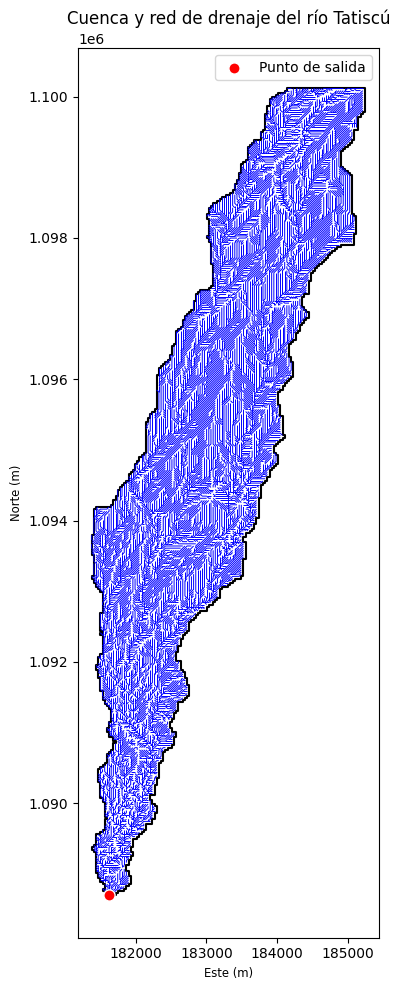

In [1369]:
# Figura de cuenca y red, Río Tatiscú
import matplotlib.pyplot as plt

cuenca_utm = gdf_geo.to_crs(UTM)
red_utm = gdf_red.to_crs(UTM)

fig, ax = plt.subplots(figsize=(10, 10))

cuenca_utm.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

red_utm.plot(
    ax=ax,
    color="blue",
    linewidth=0.7
)

ax.scatter(
    x, y,
    color="red",
    edgecolor="white",
    s=65,
    label="Punto de salida",
    zorder=5
)

ax.set_title("Cuenca y red de drenaje del río Tatiscú")
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("mapa_final_tatiscu.png", dpi=300, bbox_inches="tight")
plt.show()

In [1370]:
!pip -q install contextily

## Mapa interactivo con 4 mapas base integrando cuenca Tatiscú

In [1371]:

# Extraer la cuenca
gdf_geo = gdf.to_crs("EPSG:4326")  # UTM a latitud/longitud
lon_s, lat_s = hacia_geo.transform(x, y)  # Punto de salida

# Mapa centrado en el punto de salida
mapa = folium.Map(
    location=[lat_s, lon_s],
    zoom_start=12,
    tiles=None
)

# 1. OpenStreetMap
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(mapa)

# 2. OpenTopoMap: relieve y topografía
folium.TileLayer(
    tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    attr="Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap",
    name="Relieve topográfico",
    subdomains="abc",
    max_zoom=17,
    control=True
).add_to(mapa)

# 3. Esri World Imagery: imágenes satelitales
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Imagen satelital",
    overlay=False,
    control=True
).add_to(mapa)

# 4. Esri World Topographic Map
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Mapa topográfico Esri",
    overlay=False,
    control=True
).add_to(mapa)

# Cuenca hidrográfica
folium.GeoJson(
    gdf_geo,
    name="Cuenca hidrográfica",
    style_function=lambda f: {
        "fillColor": "#FF0000",
        "color": "#FF0000",
        "weight": 2,
        "fillOpacity": 0.15
    }
).add_to(mapa)

# Punto de salida
folium.CircleMarker(
    [lat_s, lon_s],
    radius=7,
    color="white",
    weight=2,
    fill=True,
    fill_color="red",
    fill_opacity=1,
    tooltip="Punto de salida"
).add_to(mapa)

# Control de capas
folium.LayerControl(collapsed=False).add_to(mapa)

# Mostrar mapa
mapa


In [1372]:
# Caracterización de la microcuenca Río Tatiscú

z_cuenca = np.asarray(dem)[m]
res = abs(grid.affine.a)

gy, gx = np.gradient(np.asarray(inflated), res)
pend = np.degrees(np.arctan(np.sqrt(gx**2 + gy**2)))

red_interna = cauces_np & m
long_red = red_interna.sum() * res / 1000

print(f"Área                 : {A/1e6:.2f} km2")
print(f"Perímetro            : {P/1000:.2f} km")
print(f"Elevación mínima     : {z_cuenca.min():.0f} msnm")
print(f"Elevación máxima     : {z_cuenca.max():.0f} msnm")
print(f"Elevación media      : {z_cuenca.mean():.0f} msnm")
print(f"Desnivel             : {z_cuenca.max() - z_cuenca.min():.0f} m")
print(f"Pendiente media      : {pend[m].mean():.1f}°  ({np.tan(np.radians(pend[m].mean()))*100:.0f} %)")
print(f"Pendiente máxima     : {pend[m].max():.1f}°  ({np.tan(np.radians(pend[m].max()))*100:.0f} %)")
print(f"Longitud de cauces   : {long_red:.1f} km")
print(f"Densidad de drenaje  : {long_red/(A/1e6):.2f} km/km2")


Área                 : 16.50 km2
Perímetro            : 34.37 km
Elevación mínima     : 1289 msnm
Elevación máxima     : 2626 msnm
Elevación media      : 1848 msnm
Desnivel             : 1337 m
Pendiente media      : 8.3°  (15 %)
Pendiente máxima     : 37.5°  (77 %)
Longitud de cauces   : 21.0 km
Densidad de drenaje  : 1.27 km/km2


La microcuenca del río Tatiscú se ubica al norte de Cartago, en las faldas del volcán Irazú. Se seleccionó por su interés hidrológico y por estudios sobre las cuencas de Tatiscú y Páez [UCR, 2014–2016](https://www.vinv.ucr.ac.cr/sigpro/web/projects/B4085), así como por la evaluación de afectaciones al talud de un puente sobre el Tatiscú tras lluvias intensas [LanammeUCR, 2021](https://www.lanamme.ucr.ac.cr/repositorio/bitstream/handle/50625112500/2700/EIC-Lanamme-INF-0388-2021%20Informe%20de%20evaluaci%C3%B3n%20del%20talud%20de%20aproximaci%C3%B3n%20al%20puente%20sobre%20el%20r%C3%ADo%20Tatisc%C3%BA%20en%20Ruta%20Nacional%20N%C2%B0219.pdf?isAllowed=y&sequence=1). La parte alta es importante para el riego agrícola, mientras que la baja presenta un entorno urbano-residencial. Su área de 16,50 km², pendiente media de 8,3° y desnivel de 1337 m sugieren una respuesta potencialmente rápida ante lluvias intensas. La delimitación del punto de salida es incierta: el Tatiscú se une al Toyogres antes de desembocar en el Agua Caliente. Ubicarlo en esa confluencia podría incorporar áreas ajenas a la microcuenca; por ello, debe identificarse el cauce del Tatiscú antes de la unión de los tres ríos.